In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    ConfusionMatrixDisplay
)
import joblib

print("Project setup completed!")

Project setup completed!


In [2]:
# Load the dataset
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

columns = [
    "Pregnancies", "Glucose", "BloodPressure",
    "SkinThickness", "Insulin", "BMI",
    "DiabetesPedigreeFunction", "Age", "Outcome"
]

df = pd.read_csv(url, names=columns)

# Save a local copy
df.to_csv("diabetes.csv", index=False)

# Show dataset size and first five rows
print("Dataset size:", df.shape)
display(df.head())

Dataset size: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
# Check the number of examples in each class
print("Outcome counts:")
print(df["Outcome"].value_counts())

# Columns where zero indicates a missing measurement
zero_columns = [
    "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"
]

print("\nZero values before cleaning:")
print((df[zero_columns] == 0).sum())

# Replace invalid zeros with missing values
df[zero_columns] = df[zero_columns].replace(0, np.nan)

print("\nMissing values after cleaning:")
print(df.isnull().sum())

Outcome counts:
Outcome
0    500
1    268
Name: count, dtype: int64

Zero values before cleaning:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Missing values after cleaning:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [4]:
# Input features
X = df.drop(columns=["Outcome"])

# Target label
y = df["Outcome"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (614, 8)
Testing data: (154, 8)


In [5]:
# Create the model pipeline
pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="linear"))
])

# Try different values of C to tune the SVM
parameters = {
    "svm__C": [0.01, 0.1, 1, 10]
}

search = GridSearchCV(
    pipeline,
    param_grid=parameters,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

# Train using only the training data
search.fit(X_train, y_train)

# Store the best trained pipeline
model = search.best_estimator_

print("Model training completed!")
print("Best C value:", search.best_params_["svm__C"])
print(
    "Best cross-validation accuracy:",
    f"{search.best_score_ * 100:.2f}%"
)

Model training completed!
Best C value: 0.1
Best cross-validation accuracy: 77.53%


Training Accuracy: 78.18%
Testing Accuracy: 70.78%
Precision: 60.47%
Recall (Sensitivity): 48.15%


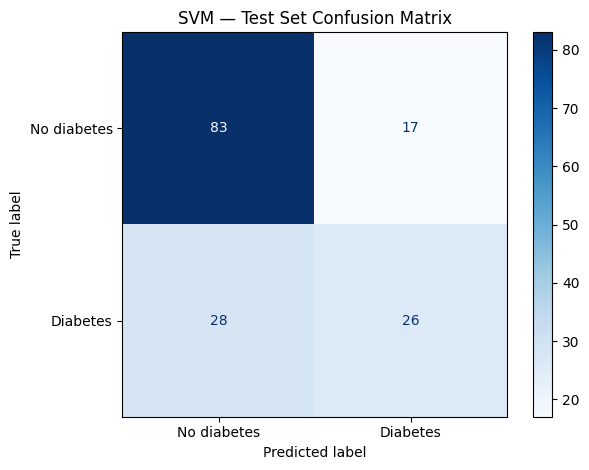

In [6]:
# Make predictions
train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)

# Calculate evaluation scores
print(
    "Training Accuracy:",
    f"{accuracy_score(y_train, train_predictions) * 100:.2f}%"
)
print(
    "Testing Accuracy:",
    f"{accuracy_score(y_test, test_predictions) * 100:.2f}%"
)
print(
    "Precision:",
    f"{precision_score(y_test, test_predictions, zero_division=0) * 100:.2f}%"
)
print(
    "Recall (Sensitivity):",
    f"{recall_score(y_test, test_predictions, zero_division=0) * 100:.2f}%"
)

# Display and save the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=["No diabetes", "Diabetes"],
    cmap="Blues",
    values_format="d"
)

plt.title("SVM — Test Set Confusion Matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

In [7]:
def predict_diabetes(
    pregnancies, glucose, blood_pressure,
    skin_thickness, insulin, bmi, pedigree, age
):
    # Keep the same column order used during training
    input_data = pd.DataFrame([[
        pregnancies, glucose, blood_pressure,
        skin_thickness, insulin, bmi, pedigree, age
    ]], columns=X_train.columns)

    # Handle missing measurements as we did during training
    input_data[zero_columns] = input_data[zero_columns].replace(
        0, np.nan
    )

    # The saved pipeline handles filling values and scaling
    prediction = int(model.predict(input_data)[0])

    if prediction == 1:
        return "Predicted class: Diabetes (1)"
    return "Predicted class: No diabetes (0)"


# Example input for demonstration
result = predict_diabetes(
    pregnancies=2,
    glucose=120,
    blood_pressure=70,
    skin_thickness=25,
    insulin=80,
    bmi=28.0,
    pedigree=0.5,
    age=35
)

print(result)
print("Educational demonstration only — not a medical diagnosis.")

Predicted class: No diabetes (0)
Educational demonstration only — not a medical diagnosis.


In [8]:
from importlib.metadata import version

# Save the complete pipeline: imputer, scaler, and SVM
joblib.dump(model, "diabetes_svm_model.joblib")

# Save a small dataset sample for submission
df.head(20).to_csv("dataset_sample.csv", index=False)

# Record the library versions used
packages = [
    "pandas", "numpy", "matplotlib", "scikit-learn", "joblib"
]

with open("requirements.txt", "w") as file:
    for package in packages:
        file.write(f"{package}=={version(package)}\n")

# Check that the saved model works after loading
loaded_model = joblib.load("diabetes_svm_model.joblib")

assert np.array_equal(
    model.predict(X_test),
    loaded_model.predict(X_test)
)

print("Model saved and checked successfully!")
print("Dataset sample saved!")
print("requirements.txt saved!")

Model saved and checked successfully!
Dataset sample saved!
requirements.txt saved!


In [9]:
readme = f"""# Diabetes Prediction using SVM

## Overview
An educational machine learning project that classifies diabetes
outcomes using the PIMA Indians Diabetes dataset.

## Dataset
- 768 records
- 8 input features and 1 target column (Outcome)
- Outcome: 0 = No diabetes, 1 = Diabetes
- Source: https://github.com/jbrownlee/Datasets

## Method
1. Replace invalid zero measurements with missing values.
2. Split data into 80% training and 20% testing.
3. Fill missing values using median imputation.
4. Standardize features using StandardScaler.
5. Train a linear Support Vector Machine.
6. Tune C using five-fold cross-validation on training data.

Imputation and scaling are inside the pipeline to prevent data leakage.

## Results
- Training accuracy: {accuracy_score(y_train, train_predictions):.2%}
- Testing accuracy: {accuracy_score(y_test, test_predictions):.2%}
- Precision: {precision_score(y_test, test_predictions, zero_division=0):.2%}
- Recall / Sensitivity: {recall_score(y_test, test_predictions, zero_division=0):.2%}
- Best C: {search.best_params_["svm__C"]}

![Confusion Matrix](confusion_matrix.png)

## Files
- Diabetes_Prediction_SVM.ipynb: Executed project notebook
- diabetes.csv: Original dataset with column names
- dataset_sample.csv: Sample after invalid zeros are marked missing
- diabetes_svm_model.joblib: Trained preprocessing and SVM pipeline
- confusion_matrix.png: Test-set evaluation chart
- requirements.txt: Python dependencies

## How to Run
Open Diabetes_Prediction_SVM.ipynb in Google Colab and run
the cells from top to bottom. Internet access is required
to load the dataset.

For local use, install dependencies with:
pip install -r requirements.txt

Use the predict_diabetes() function in the notebook to try example inputs.

## Limitations
Performance is measured on one held-out dataset split.
Results may not generalize to other populations.
This project is for educational use, not medical diagnosis.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme)

print("README.md created successfully!")

README.md created successfully!


In [10]:
import zipfile
from google.colab import files

project_files = [
    "README.md",
    "diabetes.csv",
    "dataset_sample.csv",
    "diabetes_svm_model.joblib",
    "confusion_matrix.png",
    "requirements.txt"
]

with zipfile.ZipFile(
    "Diabetes_Prediction_SVM.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as zip_file:
    for filename in project_files:
        zip_file.write(filename)

files.download("Diabetes_Prediction_SVM.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>